DEVICE: cuda:0
GPU: Tesla T4
Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).
Dataset found: /content/gdrive/MyDrive/tomato_grey_refined_segmented_COMPLETE

Source images: 18160
Source classes: 10
Copying images from Drive to local storage...
Copy complete in 5.25 minutes.
Local dataset: /content/tomato_grey_refined_segmented_COMPLETE
Verified images: 18160

Class distribution:
Tomato___Bacterial_spot: 2127
Tomato___Early_blight: 1000
Tomato___Late_blight: 1909
Tomato___Leaf_Mold: 952
Tomato___Septoria_leaf_spot: 1771
Tomato___Spider_mites Two-spotted_spider_mite: 1676
Tomato___Target_Spot: 1404
Tomato___Tomato_Yellow_Leaf_Curl_Virus: 5357
Tomato___Tomato_mosaic_virus: 373
Tomato___healthy: 1591

Split sizes: train=12712, validation=2724, test=2724

Image batch shape: torch.Size([32, 3, 224, 224])

Loading ImageNet pretrained EfficientNet-B0...
Downloading: "https://download.pytorch.org/models/efficientne

100%|██████████| 20.5M/20.5M [00:00<00:00, 114MB/s] 


Model: EfficientNet-B0
Model device: cuda:0
AMP enabled: True

==================== Warm-up ====================
Warm-up Epoch 1/3 | train_loss=0.8756 train_acc=73.6863% | val_loss=0.4384 val_acc=87.1880% | 94.3s
  Best validation checkpoint saved.
Warm-up Epoch 2/3 | train_loss=0.5503 train_acc=82.2058% | val_loss=0.3527 val_acc=88.9868% | 88.8s
  Best validation checkpoint saved.
Warm-up Epoch 3/3 | train_loss=0.4906 train_acc=84.0387% | val_loss=0.3276 val_acc=89.3172% | 88.3s
  Best validation checkpoint saved.

==================== Fine-tuning ====================
Fine-tuning Epoch 1/20 | train_loss=0.2750 train_acc=90.5994% | val_loss=0.0885 val_acc=97.2834% | 100.8s
  Best validation checkpoint saved.
Fine-tuning Epoch 2/20 | train_loss=0.1251 train_acc=95.7284% | val_loss=0.0485 val_acc=98.6050% | 97.6s
  Best validation checkpoint saved.
Fine-tuning Epoch 3/20 | train_loss=0.0878 train_acc=97.0894% | val_loss=0.0435 val_acc=98.5683% | 97.8s
Fine-tuning Epoch 4/20 | train_loss=

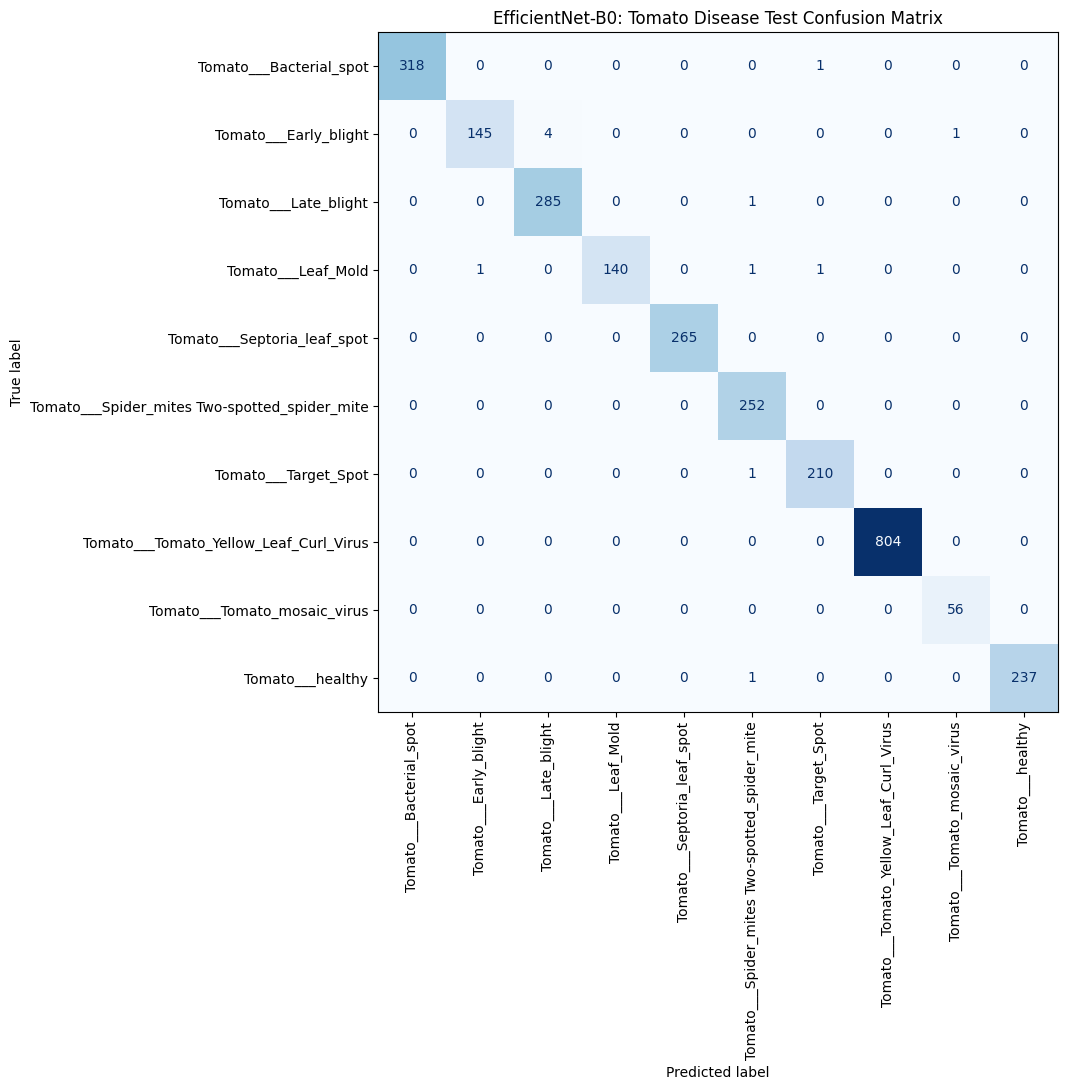

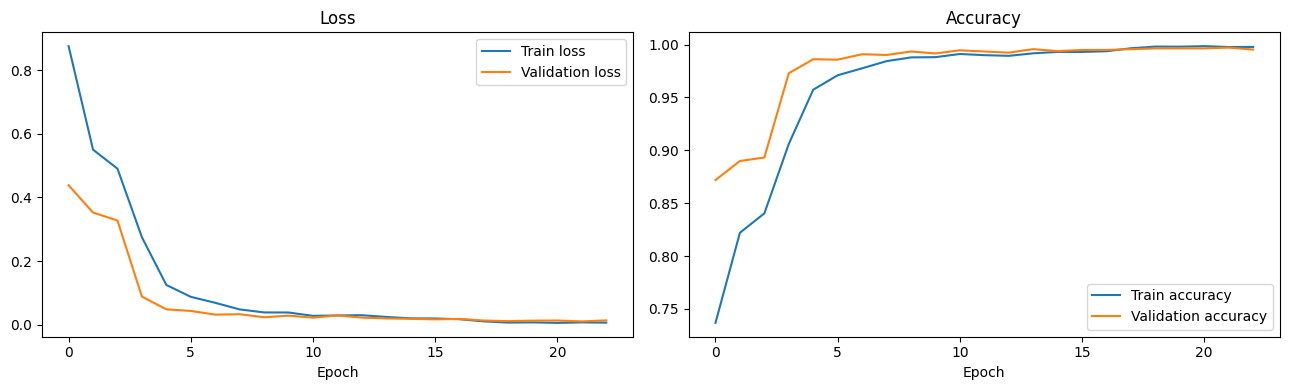


PIPELINE COMPLETE
Saved model and reports: /content/drive/MyDrive/tomato_efficientnet_b0_results
Best checkpoint: /content/drive/MyDrive/tomato_efficientnet_b0_results/best_efficientnet_b0.pth


In [3]:

# ================================================================
# TOMATO LEAF DISEASE CLASSIFICATION — COMPLETE SINGLE-CELL PIPELINE
# EfficientNet-B0 | 10 classes | Transfer learning + fine-tuning
# Drive -> Local disk -> Train -> Evaluate -> Backup to Drive
# ================================================================

import os
import time
import json
import random
import shutil
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

# ----------------------- CONFIGURATION ----------------------------

SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2
WARMUP_EPOCHS = 3
FINETUNE_EPOCHS = 20
PATIENCE = 5

DRIVE_DATASET = Path(
    "/content/drive/MyDrive/tomato_grey_refined_segmented_COMPLETE"
)
LOCAL_DATASET = Path(
    "/content/tomato_grey_refined_segmented_COMPLETE"
)
RESULT_DIR = Path(
    "/content/drive/MyDrive/tomato_efficientnet_b0_results"
)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_CLASSES = [
    "Tomato___Bacterial_spot",
    "Tomato___Early_blight",
    "Tomato___Late_blight",
    "Tomato___Leaf_Mold",
    "Tomato___Septoria_leaf_spot",
    "Tomato___Spider_mites Two-spotted_spider_mite",
    "Tomato___Target_Spot",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato___Tomato_mosaic_virus",
    "Tomato___healthy",
]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

print("=" * 65)
print("DEVICE:", DEVICE)
if USE_AMP:
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU unavailable; training will use CPU.")
print("=" * 65)

# ----------------------- 1. MOUNT DRIVE ---------------------------

from google.colab import drive
import os

MOUNT_POINT = "/content/drive"

if os.path.isdir(MOUNT_POINT) and os.path.ismount(MOUNT_POINT):
    print("Google Drive is already mounted.")
else:
    # Use a fresh mount point if /content/drive is occupied.
    if os.path.exists(MOUNT_POINT) and os.listdir(MOUNT_POINT):
        MOUNT_POINT = "/content/gdrive"
        os.makedirs(MOUNT_POINT, exist_ok=True)

    drive.mount(MOUNT_POINT)

from pathlib import Path

DRIVE_DATASET = Path(
    os.path.join(
        MOUNT_POINT,
        "MyDrive",
        "tomato_grey_refined_segmented_COMPLETE"
    )
)

assert os.path.isdir(DRIVE_DATASET), (
    f"Dataset not found at: {DRIVE_DATASET}\n"
    "Check the Google Drive mount and dataset folder name."
)

print("Dataset found:", DRIVE_DATASET)

assert DRIVE_DATASET.is_dir(), (
    f"Dataset not found: {DRIVE_DATASET}"
)

def count_images(folder):
    extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    return sum(
        1 for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    )

source_classes = sorted(
    p.name for p in DRIVE_DATASET.iterdir() if p.is_dir()
)

assert set(source_classes) == set(EXPECTED_CLASSES), (
    f"Class folders mismatch!\nFound: {source_classes}"
)

source_count = count_images(DRIVE_DATASET)
assert source_count > 0, "No images found."

print("\nSource images:", source_count)
print("Source classes:", len(source_classes))

# ----------------------- 2. COPY TO LOCAL DISK --------------------

local_valid = (
    LOCAL_DATASET.is_dir()
    and sorted(
        p.name for p in LOCAL_DATASET.iterdir() if p.is_dir()
    ) == source_classes
    and count_images(LOCAL_DATASET) == source_count
)

if local_valid:
    print("Valid local dataset exists; reusing it.")
else:
    if LOCAL_DATASET.exists():
        shutil.rmtree(LOCAL_DATASET)

    print("Copying images from Drive to local storage...")
    copy_start = time.time()
    shutil.copytree(DRIVE_DATASET, LOCAL_DATASET)

    local_count = count_images(LOCAL_DATASET)
    assert local_count == source_count, (
        f"Copy verification failed: {local_count} vs {source_count}"
    )
    print(f"Copy complete in {(time.time()-copy_start)/60:.2f} minutes.")

print("Local dataset:", LOCAL_DATASET)
print("Verified images:", count_images(LOCAL_DATASET))

# ----------------------- 3. LOAD DATASET --------------------------

base_dataset = ImageFolder(root=str(LOCAL_DATASET))
class_names = base_dataset.classes
targets = np.asarray(base_dataset.targets)
indices = np.arange(len(targets))

assert len(class_names) == 10
print("\nClass distribution:")
for i, name in enumerate(class_names):
    print(f"{name}: {int((targets == i).sum())}")

# Stratified 70/15/15 split
train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED,
    stratify=targets
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=targets[temp_idx]
)

print(
    f"\nSplit sizes: train={len(train_idx)}, "
    f"validation={len(val_idx)}, test={len(test_idx)}"
)

# Save the exact split indices for reproducibility
np.savez(
    "/content/tomato_split_indices.npz",
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx,
    class_names=np.array(class_names)
)

# ----------------------- 4. TRANSFORMS ----------------------------

MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.12,
        contrast=0.12,
        saturation=0.10,
        hue=0.02
    ),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class TomatoSubset(Dataset):
    def __init__(self, base, idx, transform):
        self.base = base
        self.idx = list(map(int, idx))
        self.transform = transform

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, position):
        path, label = self.base.samples[self.idx[position]]
        with Image.open(path) as img:
            img = img.convert("RGB")
            x = self.transform(img)
        return x, label

train_ds = TomatoSubset(base_dataset, train_idx, train_transform)
val_ds = TomatoSubset(base_dataset, val_idx, eval_transform)
test_ds = TomatoSubset(base_dataset, test_idx, eval_transform)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=USE_AMP,
    persistent_workers=(NUM_WORKERS > 0)
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=USE_AMP,
    persistent_workers=(NUM_WORKERS > 0)
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=USE_AMP,
    persistent_workers=(NUM_WORKERS > 0)
)

print("\nImage batch shape:", next(iter(train_loader))[0].shape)

# ----------------------- 5. MODEL ---------------------------------

print("\nLoading ImageNet pretrained EfficientNet-B0...")
weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)

in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, len(class_names))
model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()

# Modern PyTorch mixed precision; enabled only on CUDA
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

print("Model:", "EfficientNet-B0")
print("Model device:", next(model.parameters()).device)
print("AMP enabled:", USE_AMP)

# ----------------------- 6. TRAINING FUNCTIONS --------------------

def run_epoch(loader, training, optimizer=None):
    model.train(training)
    total_loss = 0.0
    correct = 0
    total = 0

    context = torch.enable_grad() if training else torch.no_grad()

    with context:
        for x, y in loader:
            x = x.to(DEVICE, non_blocking=USE_AMP)
            y = y.to(DEVICE, non_blocking=USE_AMP)

            if training:
                optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP
            ):
                logits = model(x)
                loss = criterion(logits, y)

            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            total_loss += loss.item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            total += y.size(0)

    return total_loss / total, correct / total

best_val_acc = -1.0
best_state = None
no_improve = 0
history = []

LOCAL_CHECKPOINT = Path("/content/best_efficientnet_b0.pth")

def train_stage(stage_name, epochs, lr, early_stop=False):
    global best_val_acc, best_state, no_improve

    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=lr,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.3, patience=2, min_lr=1e-7
    )

    print(f"\n{'='*20} {stage_name} {'='*20}")

    for epoch in range(1, epochs + 1):
        t0 = time.time()

        train_loss, train_acc = run_epoch(
            train_loader, True, optimizer
        )
        val_loss, val_acc = run_epoch(val_loader, False)

        scheduler.step(val_acc)

        row = {
            "stage": stage_name,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "learning_rate": optimizer.param_groups[0]["lr"],
            "seconds": time.time() - t0
        }
        history.append(row)

        print(
            f"{stage_name} Epoch {epoch}/{epochs} | "
            f"train_loss={train_loss:.4f} "
            f"train_acc={train_acc:.4%} | "
            f"val_loss={val_loss:.4f} "
            f"val_acc={val_acc:.4%} | "
            f"{row['seconds']:.1f}s"
        )

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0

            torch.save({
                "model_state_dict": best_state,
                "class_names": class_names,
                "image_size": IMAGE_SIZE,
                "mean": MEAN,
                "std": STD,
                "best_val_accuracy": best_val_acc
            }, LOCAL_CHECKPOINT)

            print("  Best validation checkpoint saved.")
        else:
            no_improve += 1

        if early_stop and no_improve >= PATIENCE:
            print("Early stopping triggered.")
            break

# ----------------------- 7. WARM-UP -------------------------------

# Freeze feature extractor; train only the new classification head
for p in model.features.parameters():
    p.requires_grad = False
for p in model.classifier.parameters():
    p.requires_grad = True

train_stage("Warm-up", WARMUP_EPOCHS, lr=1e-3)

# ----------------------- 8. FINE-TUNE ------------------------------

# Restore best weights before unfreezing
checkpoint = torch.load(
    LOCAL_CHECKPOINT, map_location=DEVICE, weights_only=False
)
model.load_state_dict(checkpoint["model_state_dict"])

for p in model.features.parameters():
    p.requires_grad = True
for p in model.classifier.parameters():
    p.requires_grad = True

train_stage(
    "Fine-tuning",
    FINETUNE_EPOCHS,
    lr=1e-4,
    early_stop=True
)

# Load the best model across both stages
checkpoint = torch.load(
    LOCAL_CHECKPOINT, map_location=DEVICE, weights_only=False
)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()

# ----------------------- 9. FINAL TEST EVALUATION -----------------

y_true, y_pred = [], []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(DEVICE, non_blocking=USE_AMP)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP
        ):
            logits = model(x)

        y_pred.extend(logits.argmax(1).cpu().tolist())
        y_true.extend(y.tolist())

test_acc = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n" + "=" * 65)
print("FINAL TEST RESULTS")
print("=" * 65)
print(f"Best validation accuracy: {best_val_acc:.4%}")
print(f"Test accuracy:            {test_acc:.4%}")
print(f"Test macro-F1:            {macro_f1:.4f}")

print("\nClassification report:")
report = classification_report(
    y_true, y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0,
    output_dict=True
)
print(pd.DataFrame(report).T.to_string())

cm = confusion_matrix(
    y_true, y_pred, labels=list(range(len(class_names)))
)

fig, ax = plt.subplots(figsize=(13, 11))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(ax=ax, xticks_rotation=90, cmap="Blues", colorbar=False)
ax.set_title("EfficientNet-B0: Tomato Disease Test Confusion Matrix")
plt.tight_layout()
plt.show()

# Training curves
history_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history_df["train_loss"], label="Train loss")
axes[0].plot(history_df["val_loss"], label="Validation loss")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history_df["train_accuracy"], label="Train accuracy")
axes[1].plot(history_df["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

# ----------------------- 10. BACKUP TO DRIVE ----------------------

history_path = Path("/content/tomato_training_history.json")
with open(history_path, "w") as f:
    json.dump(history, f, indent=2)

report_df = pd.DataFrame(report).T
report_path = Path("/content/tomato_classification_report.csv")
report_df.to_csv(report_path)

cm_path = Path("/content/tomato_confusion_matrix.csv")
pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(cm_path)

shutil.copy2(
    LOCAL_CHECKPOINT,
    RESULT_DIR / "best_efficientnet_b0.pth"
)
shutil.copy2(
    "/content/tomato_split_indices.npz",
    RESULT_DIR / "split_indices.npz"
)
shutil.copy2(
    history_path,
    RESULT_DIR / "training_history.json"
)
shutil.copy2(
    report_path,
    RESULT_DIR / "classification_report.csv"
)
shutil.copy2(
    cm_path,
    RESULT_DIR / "confusion_matrix.csv"
)

with open(RESULT_DIR / "final_metrics.json", "w") as f:
    json.dump({
        "architecture": "EfficientNet-B0",
        "classes": class_names,
        "best_validation_accuracy": float(best_val_acc),
        "test_accuracy": float(test_acc),
        "test_macro_f1": float(macro_f1),
        "seed": SEED,
        "image_size": IMAGE_SIZE,
        "split": "70/15/15 stratified"
    }, f, indent=2)

print("\n" + "=" * 65)
print("PIPELINE COMPLETE")
print("Saved model and reports:", RESULT_DIR)
print("Best checkpoint:", RESULT_DIR / "best_efficientnet_b0.pth")
print("=" * 65)


DEVICE: cuda:0
GPU: Tesla T4
Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Original RAW color dataset: /kaggle/input/plantvillage-dataset/plantvillage dataset/color
Raw tomato images: 18160
Raw tomato classes: 10

Class distribution:
Tomato___Bacterial_spot: 2127
Tomato___Early_blight: 1000
Tomato___Late_blight: 1909
Tomato___Leaf_Mold: 952
Tomato___Septoria_leaf_spot: 1771
Tomato___Spider_mites Two-spotted_spider_mite: 1676
Tomato___Target_Spot: 1404
Tomato___Tomato_Yellow_Leaf_Curl_Virus: 5357
Tomato___Tomato_mosaic_virus: 373
Tomato___healthy: 1591

Split sizes: train=12712, validation=2724, test=2724

Image batch shape: torch.Size([32, 3, 224, 224])

Loading ImageNet pretrained EfficientNet-B0...
Model: EfficientNet-B0
Model device: cuda:0
AMP enabled: True

==================== Warm-up ====================
Warm-up Epoch 1/3 | train_loss=0.7918 train_acc=77.8792% | val_loss=0.4193 val_acc=88.8399% | 97.3s
  Best validation checkpoint saved.
Warm-up Epoc

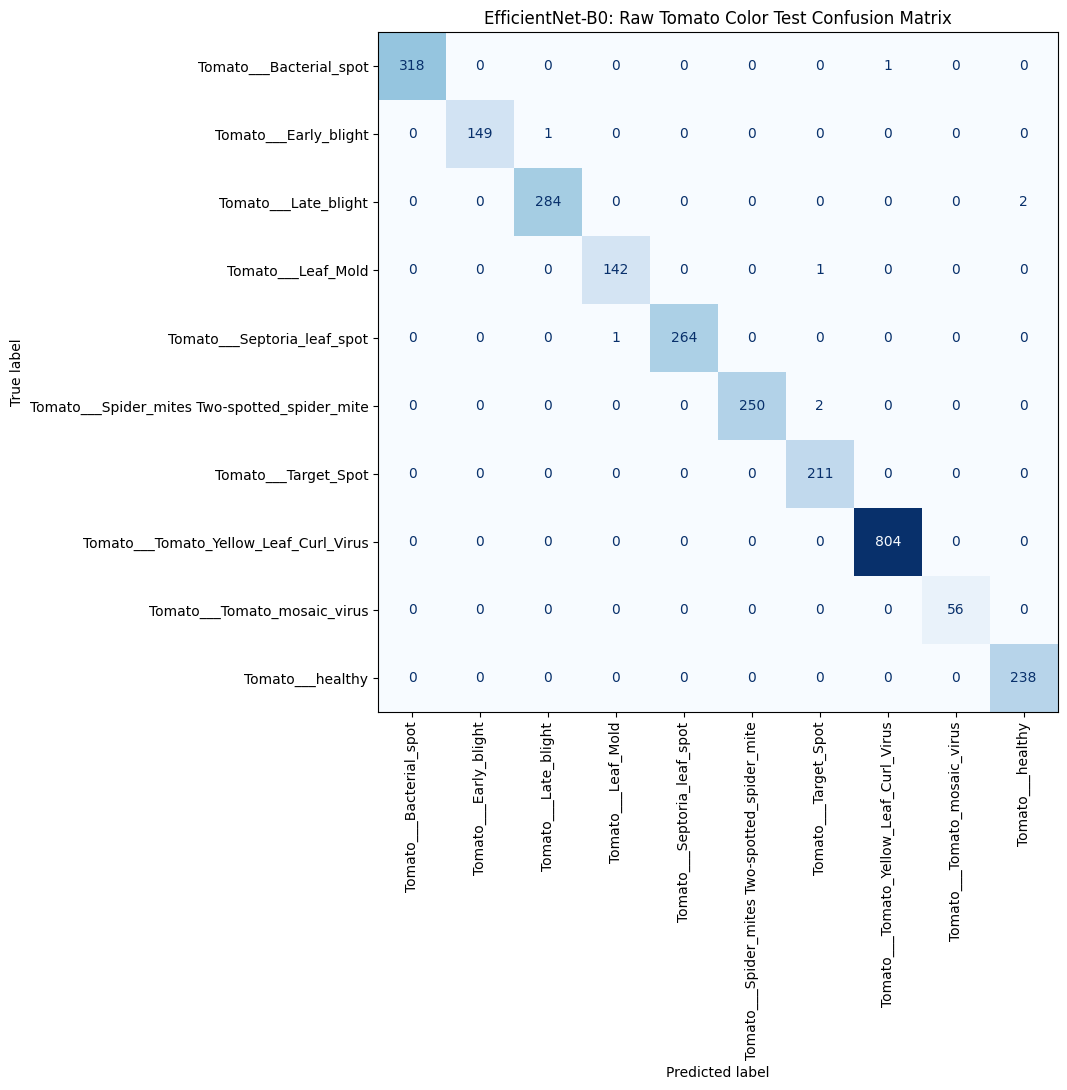

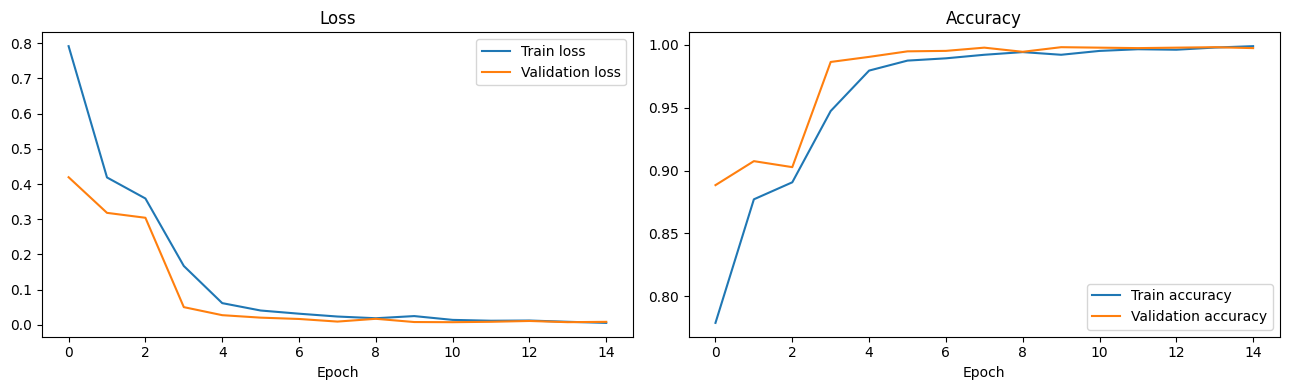


RAW COLOR EXPERIMENT COMPLETE
Dataset: /kaggle/input/plantvillage-dataset/plantvillage dataset/color
Results saved to: /content/drive/MyDrive/tomato_efficientnet_b0_raw_color_results
Best checkpoint: /content/drive/MyDrive/tomato_efficientnet_b0_raw_color_results/best_efficientnet_b0_raw_color.pth


In [7]:

# ================================================================
# TOMATO LEAF DISEASE CLASSIFICATION — RAW COLOR IMAGES
# EfficientNet-B0 | 10 classes | Transfer learning + fine-tuning
# Original training logic preserved for fair comparison
# KaggleHub color dataset -> Train -> Evaluate -> Save results
# ================================================================

import os
import time
import json
import random
import shutil
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

# ----------------------- CONFIGURATION ----------------------------

SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2
WARMUP_EPOCHS = 3
FINETUNE_EPOCHS = 20
PATIENCE = 5

# Drive is already mounted. Do not mount it again.
assert os.path.isdir("/content/drive/MyDrive"), (
    "Google Drive is not mounted. Mount it separately, then rerun."
)

# Separate folder so the segmented experiment is not overwritten.
RESULT_DIR = Path(
    "/content/drive/MyDrive/tomato_efficientnet_b0_raw_color_results"
)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_CLASSES = [
    "Tomato___Bacterial_spot",
    "Tomato___Early_blight",
    "Tomato___Late_blight",
    "Tomato___Leaf_Mold",
    "Tomato___Septoria_leaf_spot",
    "Tomato___Spider_mites Two-spotted_spider_mite",
    "Tomato___Target_Spot",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato___Tomato_mosaic_virus",
    "Tomato___healthy",
]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

print("=" * 65)
print("DEVICE:", DEVICE)
if USE_AMP:
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU unavailable; training will use CPU.")
print("=" * 65)

# ----------------------- 1. GET KAGGLE COLOR DATASET ---------------

# KaggleHub stores the dataset in its Colab runtime cache.
# No dataset copy to Google Drive or another local dataset folder.

dataset_root = Path(
    kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")
)

possible_paths = [
    dataset_root / "plantvillage dataset" / "color",
    dataset_root / "PlantVillage" / "color",
    dataset_root / "color",
]

COLOR_DIR = next((p for p in possible_paths if p.is_dir()), None)

if COLOR_DIR is None:
    COLOR_DIR = next(
        (p for p in dataset_root.rglob("color") if p.is_dir()),
        None
    )

if COLOR_DIR is None:
    raise FileNotFoundError(
        f"Could not find the PlantVillage color folder inside {dataset_root}"
    )

print("Original RAW color dataset:", COLOR_DIR)

source_classes = sorted(
    p.name for p in COLOR_DIR.iterdir()
    if p.is_dir() and p.name.startswith("Tomato___")
)

assert set(source_classes) == set(EXPECTED_CLASSES), (
    f"Tomato class folders mismatch!\nFound: {source_classes}"
)

def count_images(folder):
    extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    return sum(
        1 for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    )

source_count = sum(count_images(COLOR_DIR / name) for name in source_classes)

assert source_count > 0, "No raw tomato images found."

print("Raw tomato images:", source_count)
print("Raw tomato classes:", len(source_classes))

# ImageFolder needs one root containing the selected class folders.
# Symlinks provide a lightweight view of the original images.
# The image files themselves are NOT copied.
LINK_ROOT = Path("/content/plantvillage_tomato_raw_color_links")
LINK_ROOT.mkdir(parents=True, exist_ok=True)

for class_name in source_classes:
    source = COLOR_DIR / class_name
    link = LINK_ROOT / class_name

    if link.is_symlink() or link.is_file():
        link.unlink()
    elif link.is_dir():
        shutil.rmtree(link)

    link.symlink_to(source, target_is_directory=True)

base_dataset = ImageFolder(root=str(LINK_ROOT))
class_names = base_dataset.classes
targets = np.asarray(base_dataset.targets)
indices = np.arange(len(targets))

assert set(class_names) == set(EXPECTED_CLASSES)
assert len(base_dataset) == source_count, (
    f"Image count mismatch: ImageFolder found {len(base_dataset)}, "
    f"but source count was {source_count}"
)

print("\nClass distribution:")
for i, name in enumerate(class_names):
    print(f"{name}: {int((targets == i).sum())}")

# ----------------------- 2. STRATIFIED 70/15/15 SPLIT --------------

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED,
    stratify=targets
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=targets[temp_idx]
)

print(
    f"\nSplit sizes: train={len(train_idx)}, "
    f"validation={len(val_idx)}, test={len(test_idx)}"
)

# Save the exact split indices for reproducibility.
np.savez(
    "/content/tomato_split_indices_raw_color.npz",
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx,
    class_names=np.array(class_names)
)

# Save image paths and their split assignments for comparison.
split_map = np.empty(len(indices), dtype=object)
split_map[train_idx] = "train"
split_map[val_idx] = "validation"
split_map[test_idx] = "test"

pd.DataFrame({
    "image_path": [base_dataset.samples[i][0] for i in indices],
    "class_name": [class_names[int(targets[i])] for i in indices],
    "split": split_map
}).to_csv(RESULT_DIR / "raw_color_split.csv", index=False)

# ----------------------- 3. TRANSFORMS -----------------------------

MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.12,
        contrast=0.12,
        saturation=0.10,
        hue=0.02
    ),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class TomatoSubset(Dataset):
    def __init__(self, base, idx, transform):
        self.base = base
        self.idx = list(map(int, idx))
        self.transform = transform

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, position):
        path, label = self.base.samples[self.idx[position]]
        with Image.open(path) as img:
            img = img.convert("RGB")
            x = self.transform(img)
        return x, label

train_ds = TomatoSubset(base_dataset, train_idx, train_transform)
val_ds = TomatoSubset(base_dataset, val_idx, eval_transform)
test_ds = TomatoSubset(base_dataset, test_idx, eval_transform)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=USE_AMP,
    persistent_workers=(NUM_WORKERS > 0)
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=USE_AMP,
    persistent_workers=(NUM_WORKERS > 0)
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=USE_AMP,
    persistent_workers=(NUM_WORKERS > 0)
)

print("\nImage batch shape:", next(iter(train_loader))[0].shape)

# ----------------------- 4. MODEL ----------------------------------

print("\nLoading ImageNet pretrained EfficientNet-B0...")
weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)

in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, len(class_names))
model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()

# Same mixed-precision behavior as the original experiment.
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

print("Model:", "EfficientNet-B0")
print("Model device:", next(model.parameters()).device)
print("AMP enabled:", USE_AMP)

# ----------------------- 5. TRAINING FUNCTIONS ---------------------

def run_epoch(loader, training, optimizer=None):
    model.train(training)
    total_loss = 0.0
    correct = 0
    total = 0

    context = torch.enable_grad() if training else torch.no_grad()

    with context:
        for x, y in loader:
            x = x.to(DEVICE, non_blocking=USE_AMP)
            y = y.to(DEVICE, non_blocking=USE_AMP)

            if training:
                optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP
            ):
                logits = model(x)
                loss = criterion(logits, y)

            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            total_loss += loss.item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            total += y.size(0)

    return total_loss / total, correct / total

best_val_acc = -1.0
best_state = None
no_improve = 0
history = []

LOCAL_CHECKPOINT = Path("/content/best_efficientnet_b0_raw_color.pth")

def train_stage(stage_name, epochs, lr, early_stop=False):
    global best_val_acc, best_state, no_improve

    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=lr,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.3, patience=2, min_lr=1e-7
    )

    print(f"\n{'='*20} {stage_name} {'='*20}")

    for epoch in range(1, epochs + 1):
        t0 = time.time()

        train_loss, train_acc = run_epoch(
            train_loader, True, optimizer
        )
        val_loss, val_acc = run_epoch(val_loader, False)

        scheduler.step(val_acc)

        row = {
            "stage": stage_name,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "learning_rate": optimizer.param_groups[0]["lr"],
            "seconds": time.time() - t0
        }
        history.append(row)

        print(
            f"{stage_name} Epoch {epoch}/{epochs} | "
            f"train_loss={train_loss:.4f} "
            f"train_acc={train_acc:.4%} | "
            f"val_loss={val_loss:.4f} "
            f"val_acc={val_acc:.4%} | "
            f"{row['seconds']:.1f}s"
        )

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0

            torch.save({
                "model_state_dict": best_state,
                "class_names": class_names,
                "image_size": IMAGE_SIZE,
                "mean": MEAN,
                "std": STD,
                "best_val_accuracy": best_val_acc
            }, LOCAL_CHECKPOINT)

            print("  Best validation checkpoint saved.")
        else:
            no_improve += 1

        if early_stop and no_improve >= PATIENCE:
            print("Early stopping triggered.")
            break

# ----------------------- 6. WARM-UP -------------------------------

# Freeze feature extractor; train only the new classification head.
for p in model.features.parameters():
    p.requires_grad = False
for p in model.classifier.parameters():
    p.requires_grad = True

train_stage("Warm-up", WARMUP_EPOCHS, lr=1e-3)

# ----------------------- 7. FINE-TUNE -------------------------------

# Original checkpoint restoration and loop behavior preserved.
checkpoint = torch.load(
    LOCAL_CHECKPOINT, map_location=DEVICE, weights_only=False
)
model.load_state_dict(checkpoint["model_state_dict"])

for p in model.features.parameters():
    p.requires_grad = True
for p in model.classifier.parameters():
    p.requires_grad = True

train_stage(
    "Fine-tuning",
    FINETUNE_EPOCHS,
    lr=1e-4,
    early_stop=True
)

# Load the best checkpoint across both stages.
checkpoint = torch.load(
    LOCAL_CHECKPOINT, map_location=DEVICE, weights_only=False
)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()

# ----------------------- 8. FINAL TEST EVALUATION ------------------

y_true, y_pred = [], []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(DEVICE, non_blocking=USE_AMP)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP
        ):
            logits = model(x)

        y_pred.extend(logits.argmax(1).cpu().tolist())
        y_true.extend(y.tolist())

test_acc = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("\n" + "=" * 65)
print("RAW COLOR IMAGE FINAL TEST RESULTS")
print("=" * 65)
print(f"Best validation accuracy: {best_val_acc:.4%}")
print(f"Test accuracy:            {test_acc:.4%}")
print(f"Test macro-F1:            {macro_f1:.4f}")

print("\nClassification report:")
report = classification_report(
    y_true, y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0,
    output_dict=True
)
report_df = pd.DataFrame(report).T
print(report_df.to_string())
report_df.to_csv(RESULT_DIR / "classification_report.csv")

cm = confusion_matrix(
    y_true, y_pred, labels=list(range(len(class_names)))
)

fig, ax = plt.subplots(figsize=(13, 11))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(ax=ax, xticks_rotation=90, cmap="Blues", colorbar=False)
ax.set_title("EfficientNet-B0: Raw Tomato Color Test Confusion Matrix")
plt.tight_layout()
plt.savefig(RESULT_DIR / "confusion_matrix.png", dpi=200)
plt.show()

pd.DataFrame(
    cm, index=class_names, columns=class_names
).to_csv(RESULT_DIR / "confusion_matrix.csv")

# ----------------------- 9. TRAINING CURVES ------------------------

history_df = pd.DataFrame(history)
history_df.to_csv(RESULT_DIR / "training_history.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history_df["train_loss"], label="Train loss")
axes[0].plot(history_df["val_loss"], label="Validation loss")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history_df["train_accuracy"], label="Train accuracy")
axes[1].plot(history_df["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.savefig(RESULT_DIR / "training_curves.png", dpi=200)
plt.show()

# ----------------------- 10. SAVE RESULTS --------------------------

history_path = Path("/content/tomato_training_history_raw_color.json")
with open(history_path, "w") as f:
    json.dump(history, f, indent=2)

shutil.copy2(
    LOCAL_CHECKPOINT,
    RESULT_DIR / "best_efficientnet_b0_raw_color.pth"
)
shutil.copy2(
    "/content/tomato_split_indices_raw_color.npz",
    RESULT_DIR / "split_indices.npz"
)
shutil.copy2(
    history_path,
    RESULT_DIR / "training_history.json"
)

with open(RESULT_DIR / "final_metrics.json", "w") as f:
    json.dump({
        "dataset": "Kaggle PlantVillage color (raw images)",
        "architecture": "EfficientNet-B0",
        "classes": class_names,
        "best_validation_accuracy": float(best_val_acc),
        "test_accuracy": float(test_acc),
        "test_macro_f1": float(macro_f1),
        "seed": SEED,
        "image_size": IMAGE_SIZE,
        "batch_size": BATCH_SIZE,
        "warmup_epochs_max": WARMUP_EPOCHS,
        "finetune_epochs_max": FINETUNE_EPOCHS,
        "patience": PATIENCE,
        "split": "70/15/15 stratified"
    }, f, indent=2)

print("\n" + "=" * 65)
print("RAW COLOR EXPERIMENT COMPLETE")
print("Dataset:", COLOR_DIR)
print("Results saved to:", RESULT_DIR)
print("Best checkpoint:", RESULT_DIR / "best_efficientnet_b0_raw_color.pth")
print("=" * 65)
